# CAIRLab Hackathon — Day 2 Extension: Intermediate + Advanced Tracks

Two new tracks unlock today, and you're free to attempt either or both between now and the
submission deadline:

| Track | Goal |
|---|---|
| 🟡 Intermediate | Client data is realistically **skewed** across the five banks — naive FedAvg performs worse under this skew. Fix the **aggregation**. |
| 🔴 Advanced (optional) | Partway through, one bank turns malicious and sends sabotaged updates. **Detect or resist** the attack. |

This notebook is self-contained — it rebuilds the dataset, partitions, model, and FL harness
from scratch, so you don't need yesterday's notebook open. The ideas carry over directly:
same story, same weak baseline, same FedAvg loop as Day 1, extended with what you need for
today's tracks.

**Scoring today:** unlike Day 1, these tracks aren't on a Kaggle leaderboard — a static
prediction file can't capture "how your aggregation holds up under skew" or "how much F1 your
defense recovers under attack." Instead, you'll report your before/after comparison in your
Kaggle Writeup, and export your final model for the organizers to spot-check. See the
Evaluation Rubric on the hackathon page for exact scoring weights.


> **Team zerooth: submission notebook for both Day 2 tracks.**
> - 🟡 **Intermediate: FedNova with equal client weights.** See *Our approach* in the Intermediate section.
> - 🔴 **Advanced: FedNova-Guard**, which builds on the Intermediate method. See *Our defense* in the Advanced section.
>
> Everything above Section 5 is the organisers' notebook, unchanged. Our additions are the cells marked 🔧
> and the "Our approach / Our defense" sections that follow them. Each FL run is seeded right before it
> (`SEED = 42`), so before/after comparisons use identical randomness and each exported model's F1 matches
> the reported number. Section 8 exports **both** submissions: `submission_intermediate/` and `submission_advanced/`.
> Full experiment logs, including what failed: `docs/intermediate_experiments.md` and `docs/advanced_experiments.md`.

## 0. Setup

In [1]:

# !pip -q install torch scikit-learn pandas numpy matplotlib --upgrade 2>/dev/null
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import copy, json, os, hashlib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("data", exist_ok=True)
print("Setup complete.")


Setup complete.


## 1. Load and clean the dataset (same as Day 1)


In [2]:

TRAIN_URL = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"
TEST_URL  = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"

COLS = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty",
]

train_raw = pd.read_csv(TRAIN_URL, names=COLS)
test_raw  = pd.read_csv(TEST_URL, names=COLS)

def clean(df):
    df = df.drop(columns=["difficulty"]).copy()
    df["binary_label"] = (df["label"] != "normal").astype(int)
    return df

train_df = clean(train_raw)
test_df  = clean(test_raw)

CAT_COLS = ["protocol_type", "service", "flag"]
encoders = {}
for c in CAT_COLS:
    le = LabelEncoder()
    le.fit(pd.concat([train_df[c], test_df[c]], axis=0))
    train_df[c] = le.transform(train_df[c])
    test_df[c]  = le.transform(test_df[c])
    encoders[c] = le

FEATURE_COLS = [c for c in train_df.columns if c not in ["label", "binary_label"]]

scaler = StandardScaler()
train_df[FEATURE_COLS] = scaler.fit_transform(train_df[FEATURE_COLS])
test_df[FEATURE_COLS]  = scaler.transform(test_df[FEATURE_COLS])

print("features:", len(FEATURE_COLS))


features: 41


## 2. Partition into 5 clients — IID (for reference) and non-IID (today's data)

Same holdout reservation logic as Day 1 (same seed, so it's the identical reserved rows —
this doesn't matter for today's scoring, it's just kept consistent).

Today you also get a **non-IID** partition: the same pool of training rows, but split so
each "bank" sees a skewed slice of traffic — one might see mostly denial-of-service attacks,
another almost entirely normal traffic. This is realistic (different banks see different
customers and attackers), and it's what breaks naive FedAvg.


In [3]:

N_CLIENTS = 5
HOLDOUT_SIZE = 15000

_rng = np.random.RandomState(SEED)
_perm = _rng.permutation(len(train_df))
_holdout_idx = _perm[:HOLDOUT_SIZE]
_pool_idx = _perm[HOLDOUT_SIZE:]
train_pool = train_df.iloc[_pool_idx].reset_index(drop=True)

def make_iid_partition(df, n_clients=N_CLIENTS, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(df))
    chunks = np.array_split(idx, n_clients)
    return [df.iloc[c].reset_index(drop=True) for c in chunks]

FAMILY_MAP = {
    "normal": "normal",
    "neptune": "dos", "back": "dos", "land": "dos", "pod": "dos", "smurf": "dos",
    "teardrop": "dos", "apache2": "dos", "udpstorm": "dos", "processtable": "dos",
    "worm": "dos", "mailbomb": "dos",
    "satan": "probe", "ipsweep": "probe", "nmap": "probe", "portsweep": "probe",
    "mscan": "probe", "saint": "probe",
}

def make_noniid_partition(df, n_clients=N_CLIENTS, alpha=0.3, seed=SEED):
    '''Dirichlet-skewed split by attack family. Low alpha = strong skew.'''
    rng = np.random.RandomState(seed)
    df = df.copy()
    df["family"] = df["label"].map(lambda x: FAMILY_MAP.get(x, "r2l_u2r_other"))
    client_indices = [[] for _ in range(n_clients)]
    for fam in df["family"].unique():
        fam_idx = df.index[df["family"] == fam].to_numpy().copy()
        rng.shuffle(fam_idx)
        proportions = rng.dirichlet(alpha=[alpha] * n_clients)
        split_points = (np.cumsum(proportions) * len(fam_idx)).astype(int)[:-1]
        for i, s in enumerate(np.split(fam_idx, split_points)):
            client_indices[i].extend(s.tolist())
    out = []
    for ci in client_indices:
        rng.shuffle(ci)
        out.append(df.loc[ci].drop(columns=["family"]).reset_index(drop=True))
    return out

iid_clients = make_iid_partition(train_pool)
noniid_clients = make_noniid_partition(train_pool)

print("IID sizes:", [len(c) for c in iid_clients])
print("\\nNon-IID sizes:", [len(c) for c in noniid_clients])
for i, c in enumerate(noniid_clients):
    print(f"  client {i} label mix:", c["binary_label"].value_counts(normalize=True).round(2).to_dict())


IID sizes: [22195, 22195, 22195, 22194, 22194]
\nNon-IID sizes: [6272, 10658, 48219, 23239, 22585]
  client 0 label mix: {1: 0.81, 0: 0.19}
  client 1 label mix: {1: 0.86, 0: 0.14}
  client 2 label mix: {1: 0.68, 0: 0.32}
  client 3 label mix: {0: 0.85, 1: 0.15}
  client 4 label mix: {0: 0.96, 1: 0.04}


## 3. The weak baseline model (same as Day 1)


In [4]:

N_FEATURES = len(FEATURE_COLS)

class WeakMLP(nn.Module):
    def __init__(self, n_features=N_FEATURES, hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


## 4. The FL harness — extended with robust aggregation and attack simulation

Same local training and FedAvg as Day 1, plus what today's tracks need: a
`coordinate_median` robust-aggregation baseline, a `custom` aggregation hook, and the
ability to simulate malicious clients.


In [5]:

X_test = torch.tensor(test_df[FEATURE_COLS].values, dtype=torch.float32)
y_test = torch.tensor(test_df["binary_label"].values, dtype=torch.float32)

def df_to_tensors(df):
    X = torch.tensor(df[FEATURE_COLS].values, dtype=torch.float32)
    y = torch.tensor(df["binary_label"].values, dtype=torch.float32)
    return X, y

def local_train(model, X, y, epochs=1, lr=0.05, batch_size=256):
    model = copy.deepcopy(model)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    n = len(X)
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            loss.backward()
            opt.step()
    return model

def get_flat_params(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()])

def set_flat_params(model, flat):
    i = 0
    for p in model.parameters():
        n = p.numel()
        p.data.copy_(flat[i:i + n].view(p.shape))
        i += n

def fedavg(models, weights):
    weights = np.array(weights, dtype=float) / np.sum(weights)
    flats = torch.stack([get_flat_params(m) for m in models])
    avg = (flats * torch.tensor(weights, dtype=torch.float32).unsqueeze(1)).sum(dim=0)
    out = copy.deepcopy(models[0])
    set_flat_params(out, avg)
    return out

def coordinate_median(models):
    '''A simple robust-aggregation baseline: take the per-coordinate median of all
    client updates instead of the (weighted) mean. Outliers (e.g. a poisoned update
    with an inflated magnitude) influence the median far less than the mean.'''
    flats = torch.stack([get_flat_params(m) for m in models])
    med = flats.median(dim=0).values
    out = copy.deepcopy(models[0])
    set_flat_params(out, med)
    return out

def evaluate(model):
    model.eval()
    with torch.no_grad():
        preds = (torch.sigmoid(model(X_test)) > 0.5).float()
    return {
        "precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "f1": round(f1_score(y_test, preds, zero_division=0), 4),
    }

def run_fl(client_dfs, model_fn=lambda: WeakMLP(), rounds=8, epochs=1,
           aggregation="fedavg", agg_fn=None,
           malicious_clients=None, attack="scale", scale_factor=15.0, verbose=True):
    '''
    aggregation: "fedavg" | "median" | "custom" (use agg_fn for "custom")
    malicious_clients: list of client indices that send poisoned updates (advanced track)
    attack: "label_flip" or "scale" (scale = label_flip + inflated update magnitude)
    '''
    malicious_clients = malicious_clients or []
    global_model = model_fn()
    client_tensors = [df_to_tensors(df) for df in client_dfs]

    history = []
    for r in range(rounds):
        local_models, sizes = [], []
        global_flat = get_flat_params(global_model)

        for cid, (X, y) in enumerate(client_tensors):
            is_malicious = cid in malicious_clients
            if is_malicious:
                y = 1 - y  # label-flip
            lm = local_train(global_model, X, y, epochs=epochs)
            if is_malicious and attack == "scale":
                delta = get_flat_params(lm) - global_flat
                set_flat_params(lm, global_flat + scale_factor * delta)
            local_models.append(lm)
            sizes.append(len(X))

        prev_global_model = global_model
        if aggregation == "fedavg":
            global_model = fedavg(local_models, sizes)
        elif aggregation == "median":
            global_model = coordinate_median(local_models)
        elif aggregation == "custom":
            global_model = agg_fn(local_models, sizes, prev_global_model)
        else:
            raise ValueError(f"unknown aggregation: {aggregation}")

        metrics = evaluate(global_model)
        history.append(metrics)
        if verbose:
            print(f"round {r+1:>2}: {metrics}")

    return global_model, history


## 5. Recompute your Day 1 reference point

Quick reference run on IID data — same as your Day 1 baseline — so you have a same-session
number to compare today's non-IID results against.


In [6]:

print("Reference: weak model, IID clients, naive FedAvg")
torch.manual_seed(SEED); np.random.seed(SEED)
baseline_model, baseline_history = run_fl(iid_clients, rounds=6)
print("\\nFinal:", baseline_history[-1])


Reference: weak model, IID clients, naive FedAvg


round  1: {'precision': 0.9574, 'recall': 0.2875, 'f1': 0.4423}


round  2: {'precision': 0.9695, 'recall': 0.6026, 'f1': 0.7432}


round  3: {'precision': 0.9694, 'recall': 0.628, 'f1': 0.7622}


round  4: {'precision': 0.9315, 'recall': 0.6348, 'f1': 0.7551}


round  5: {'precision': 0.9324, 'recall': 0.6413, 'f1': 0.7599}


round  6: {'precision': 0.9324, 'recall': 0.6473, 'f1': 0.7641}
\nFinal: {'precision': 0.9324, 'recall': 0.6473, 'f1': 0.7641}


---
## 🟡 Intermediate track — fix the non-IID aggregation

Switch to the skewed client split and watch what happens with plain FedAvg.


In [7]:

print("Non-IID clients, naive FedAvg (same model, same aggregation as baseline)")
torch.manual_seed(SEED); np.random.seed(SEED)
noniid_model, noniid_history = run_fl(noniid_clients, rounds=8)
print("\\nIID F1:    ", baseline_history[-1]["f1"])
print("Non-IID F1:", noniid_history[-1]["f1"])


Non-IID clients, naive FedAvg (same model, same aggregation as baseline)


round  1: {'precision': 0.9858, 'recall': 0.2063, 'f1': 0.3412}


round  2: {'precision': 0.9863, 'recall': 0.5166, 'f1': 0.678}


round  3: {'precision': 0.9436, 'recall': 0.5359, 'f1': 0.6836}


round  4: {'precision': 0.9374, 'recall': 0.5484, 'f1': 0.692}


round  5: {'precision': 0.9371, 'recall': 0.5554, 'f1': 0.6974}


round  6: {'precision': 0.9383, 'recall': 0.5625, 'f1': 0.7034}


round  7: {'precision': 0.9408, 'recall': 0.5662, 'f1': 0.7069}


round  8: {'precision': 0.9524, 'recall': 0.5681, 'f1': 0.7117}
\nIID F1:     0.7641
Non-IID F1: 0.7117


Naive FedAvg treats every client's update as equally trustworthy and just weights by
data size. When one client's local distribution is very different from the global
distribution (e.g. almost-all-attack-traffic), its update can pull the global model in a
direction that hurts everyone else.

**Ideas to improve aggregation**, roughly in order of effort:
- Weight clients differently — e.g. down-weight clients whose local class distribution is
  most different from the (estimated) global distribution.
- **FedProx-style**: add a proximal penalty term in local training that keeps each client's
  local model from drifting too far from the current global model.
- Cluster clients by similarity of their updates and aggregate within clusters before a
  final merge.

**Your hook:** write a function with signature
`agg_fn(local_models, sizes, prev_global_model) -> model` and pass it to
`run_fl(..., aggregation="custom", agg_fn=my_agg_fn)`.


### Our approach: FedNova with equal client weights

**Diagnosis.** Under this skew, size-weighted FedAvg counts the big banks *twice*:

1. **Larger weight:** bank 2 has 48k rows (44% of the vote); bank 0 has 6k (6%).
2. **Longer update:** one local epoch is ⌈n/256⌉ SGD steps, about 190 for bank 2 and 25 for bank 0,
   so bank 2's update has also travelled ~7× further from the global model.

The big banks are mostly *normal* traffic and DoS. The small banks 0 and 1 hold ~90% of the
**probe** attacks and ~70% of the rare **R2L/U2R** attacks, and that knowledge gets drowned out.
The damage is almost all in recall, while precision stays at ~0.95.

**Fix (server-side only).**
- **FedNova** (Wang et al., 2020) divides each bank's update by its number of local steps
  τᵢ = ⌈nᵢ/256⌉, averages these *per-step* directions, and rescales by the average τ.
  This removes factor 2.
- **Equal weights** instead of size weights remove factor 1.
- A small guard skips banks that sent nothing (no data or an all-zero update); otherwise
  τ = 0 would divide by zero.

**Privacy.** The server uses only what naive FedAvg already receives: each bank's model and its
size (τ follows from the size). No label or attack-family statistics leave a bank. We tested
histogram-based weightings too (including the skeleton's label-balance idea) and deliberately
excluded them.

In [8]:
# 🔧 Intermediate track: FedNova with equal client weights
LOCAL_BATCH = 256  # local_train's batch size -> tau_i = ceil(n_i / 256) SGD steps per round

def active_only(agg):
    """Skip banks that contributed nothing this round (no data, or an all-zero update)."""
    def wrapped(local_models, sizes, prev_global_model):
        prev_flat = get_flat_params(prev_global_model)
        keep = [i for i, (m, n) in enumerate(zip(local_models, sizes))
                if n > 0 and (get_flat_params(m) - prev_flat).norm() > 0]
        if not keep:
            return copy.deepcopy(prev_global_model)
        return agg([local_models[i] for i in keep], [sizes[i] for i in keep], prev_global_model)
    return wrapped

def fednova_equal(local_models, sizes, prev_global_model):
    n = np.array(sizes, dtype=float)
    tau = np.ceil(n / LOCAL_BATCH)               # local SGD steps each bank took
    p = np.ones_like(n) / len(n)                 # equal weight per bank
    prev_flat = get_flat_params(prev_global_model)
    deltas = torch.stack([get_flat_params(m) for m in local_models]) - prev_flat
    per_step = deltas / torch.tensor(tau, dtype=torch.float32).unsqueeze(1)
    tau_eff = float((p * tau).sum())             # average number of steps
    step = tau_eff * (per_step * torch.tensor(p, dtype=torch.float32).unsqueeze(1)).sum(dim=0)
    out = copy.deepcopy(prev_global_model)
    set_flat_params(out, prev_flat + step)
    return out

my_agg_fn = active_only(fednova_equal)

torch.manual_seed(SEED); np.random.seed(SEED)   # same seed as the naive non-IID run above
custom_model, custom_history = run_fl(noniid_clients, rounds=8, aggregation="custom", agg_fn=my_agg_fn)
print("\nNaive non-IID F1:   ", noniid_history[-1]["f1"])
print("Your aggregation F1:", custom_history[-1]["f1"])
print(f"Improvement:         {custom_history[-1]['f1'] - noniid_history[-1]['f1']:+.4f}")

round  1: {'precision': 0.9625, 'recall': 0.6655, 'f1': 0.7869}


round  2: {'precision': 0.925, 'recall': 0.6757, 'f1': 0.7809}


round  3: {'precision': 0.9234, 'recall': 0.6891, 'f1': 0.7892}


round  4: {'precision': 0.9217, 'recall': 0.686, 'f1': 0.7866}


round  5: {'precision': 0.9199, 'recall': 0.6836, 'f1': 0.7844}


round  6: {'precision': 0.9182, 'recall': 0.6823, 'f1': 0.7829}


round  7: {'precision': 0.9177, 'recall': 0.6823, 'f1': 0.7827}


round  8: {'precision': 0.9173, 'recall': 0.6816, 'f1': 0.7821}

Naive non-IID F1:    0.7117
Your aggregation F1: 0.7821
Improvement:         +0.0704


### Is the gain robust? 5 training seeds

One seed can be lucky, so we re-run naive FedAvg and FedNova (equal) with training seeds 0–4.
The data split stays the notebook's. The IID FedAvg run from Section 5 is the reference line.

In [9]:
SEEDS = [0, 1, 2, 3, 4]

def runs_over_seeds(client_dfs, **kw):
    hists = []
    for s in SEEDS:
        torch.manual_seed(s); np.random.seed(s)
        _, h = run_fl(client_dfs, rounds=8, verbose=False, **kw)
        hists.append(h)
    return hists

seed_runs = {
    "IID FedAvg (reference)": runs_over_seeds(iid_clients),
    "Naive FedAvg (non-IID)": runs_over_seeds(noniid_clients),
    "FedNova, equal weights (non-IID)": runs_over_seeds(noniid_clients, aggregation="custom", agg_fn=my_agg_fn),
}
summary = pd.DataFrame({
    name: {m: f"{np.mean([h[-1][m] for h in hs]):.4f} ± {np.std([h[-1][m] for h in hs]):.4f}"
           for m in ["f1", "precision", "recall"]}
    for name, hs in seed_runs.items()
}).T
print(summary.to_string())
gain = [b[-1]["f1"] - a[-1]["f1"] for a, b in zip(seed_runs["Naive FedAvg (non-IID)"], seed_runs["FedNova, equal weights (non-IID)"])]
print(f"\nF1 gain per seed: {np.round(gain, 4).tolist()}  (mean {np.mean(gain):+.4f})")

                                               f1        precision           recall
IID FedAvg (reference)            0.7556 ± 0.0064  0.9367 ± 0.0103  0.6335 ± 0.0129
Naive FedAvg (non-IID)            0.7147 ± 0.0086  0.9512 ± 0.0183  0.5725 ± 0.0101
FedNova, equal weights (non-IID)  0.7787 ± 0.0082  0.9183 ± 0.0040  0.6760 ± 0.0106

F1 gain per seed: [0.0658, 0.0697, 0.0615, 0.0529, 0.07]  (mean +0.0640)


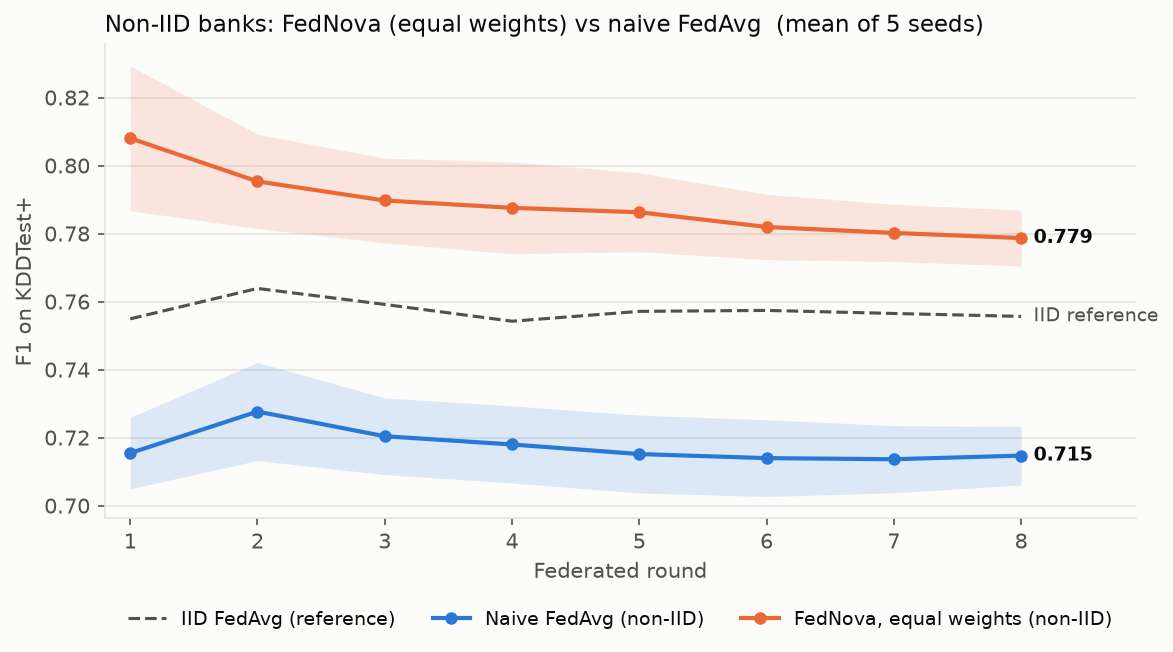

In [10]:
# F1 over rounds: mean over 5 seeds, band = ±1 std
os.makedirs("figures", exist_ok=True)
COLORS = {"Naive FedAvg (non-IID)": "#2a78d6", "FedNova, equal weights (non-IID)": "#eb6834"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
rounds = np.arange(1, 9)
iid = np.array([[m["f1"] for m in h] for h in seed_runs["IID FedAvg (reference)"]]).mean(0)
ax.plot(rounds, iid, color=MUTED, lw=1.5, ls="--", label="IID FedAvg (reference)")
ax.annotate("IID reference", (8, iid[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=MUTED, fontsize=9)
for name, color in COLORS.items():
    f1 = np.array([[m["f1"] for m in h] for h in seed_runs[name]])
    mu, sd = f1.mean(0), f1.std(0)
    ax.fill_between(rounds, mu - sd, mu + sd, color=color, alpha=0.15, lw=0)
    ax.plot(rounds, mu, color=color, lw=2, marker="o", ms=5, label=name)
    ax.annotate(f"{mu[-1]:.3f}", (8, mu[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9, fontweight="bold")
ax.set_xlabel("Federated round", color=MUTED); ax.set_ylabel("F1 on KDDTest+", color=MUTED)
ax.set_title("Non-IID banks: FedNova (equal weights) vs naive FedAvg  (mean of 5 seeds)", color=INK, fontsize=11, loc="left")
ax.set_xticks(rounds); ax.set_xlim(0.8, 8.9)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
for s in ["left", "bottom"]: ax.spines[s].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9, labelcolor=INK)
fig.tight_layout()
fig.savefig("figures/intermediate_f1_over_rounds.png", facecolor=SURFACE)
plt.show()

### Where does the gain come from?

At a fixed 0.5 threshold, a model can gain F1 just by predicting "attack" more often. So we also
report threshold-free AUC, the false-positive rate, and recall per attack family, for the two
seed-42 models above.

In [11]:
test_family = test_df["label"].map(lambda x: FAMILY_MAP.get(x, "r2l_u2r_other")).values

def diagnostics(model):
    model.eval()
    with torch.no_grad():
        score = torch.sigmoid(model(X_test)).numpy()
    y, pred = y_test.numpy(), score > 0.5
    row = {"F1": f1_score(y, pred), "AUC": roc_auc_score(y, score), "false-pos rate": pred[y == 0].mean()}
    for fam in ["dos", "probe", "r2l_u2r_other"]:
        row[f"recall {fam}"] = pred[test_family == fam].mean()
    return row

print(pd.DataFrame({"Naive FedAvg": diagnostics(noniid_model),
                    "FedNova (equal)": diagnostics(custom_model)}).T.round(4).to_string())

                     F1     AUC  false-pos rate  recall dos  recall probe  recall r2l_u2r_other
Naive FedAvg     0.7117  0.8697          0.0375      0.7787        0.5816                0.0247
FedNova (equal)  0.7821  0.9102          0.0812      0.7849        0.9665                0.1870


---
## 🔴 Advanced track (optional) — detect or resist a poisoning attack

Partway through, imagine one of your five "banks" has been compromised (or is actively
malicious) and starts sending sabotaged updates instead of honest ones. Below, client `1`
is malicious: it flips its local labels **and** inflates the magnitude of its update so it
dominates a plain average, regardless of how much data it actually has.


In [12]:
print("Non-IID + 1 malicious client (scale attack), naive FedAvg — should degrade")
torch.manual_seed(SEED); np.random.seed(SEED)
attacked_model, attacked_history = run_fl(
    noniid_clients, rounds=8,
    malicious_clients=[1], attack="scale", scale_factor=15.0,
)
print("\\nClean non-IID F1:  ", noniid_history[-1]["f1"])
print("Under attack F1:    ", attacked_history[-1]["f1"])

Non-IID + 1 malicious client (scale attack), naive FedAvg — should degrade


round  1: {'precision': 1.0, 'recall': 0.1038, 'f1': 0.1881}


round  2: {'precision': 0.9959, 'recall': 0.1128, 'f1': 0.2026}


round  3: {'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


round  4: {'precision': 0.8421, 'recall': 0.0087, 'f1': 0.0173}


round  5: {'precision': 0.8779, 'recall': 0.0118, 'f1': 0.0232}


round  6: {'precision': 0.854, 'recall': 0.0337, 'f1': 0.0649}


round  7: {'precision': 0.9868, 'recall': 0.2497, 'f1': 0.3986}


round  8: {'precision': 0.0794, 'recall': 0.0376, 'f1': 0.0511}
\nClean non-IID F1:   0.7117
Under attack F1:     0.0511


In [13]:
print("Same attack, but aggregating with the coordinate-median baseline defense")
torch.manual_seed(SEED); np.random.seed(SEED)
defended_model, defended_history = run_fl(
    noniid_clients, rounds=8,
    malicious_clients=[1], attack="scale", scale_factor=15.0,
    aggregation="median",
)
print("\\nUnder attack (naive FedAvg): ", attacked_history[-1]["f1"])
print("Under attack (median defense):", defended_history[-1]["f1"])

Same attack, but aggregating with the coordinate-median baseline defense


round  1: {'precision': 1.0, 'recall': 0.082, 'f1': 0.1515}


round  2: {'precision': 0.999, 'recall': 0.1514, 'f1': 0.263}


round  3: {'precision': 0.9991, 'recall': 0.4551, 'f1': 0.6253}


round  4: {'precision': 0.9953, 'recall': 0.4952, 'f1': 0.6614}


round  5: {'precision': 0.9884, 'recall': 0.5102, 'f1': 0.673}


round  6: {'precision': 0.988, 'recall': 0.5186, 'f1': 0.6802}


round  7: {'precision': 0.9878, 'recall': 0.5227, 'f1': 0.6837}


round  8: {'precision': 0.9875, 'recall': 0.525, 'f1': 0.6855}
\nUnder attack (naive FedAvg):  0.0511
Under attack (median defense): 0.6855


`coordinate_median` is given as a working baseline defense — notice it already recovers
some of the lost F1. That's your floor, not your ceiling. Try cranking `scale_factor` up
(e.g. 30–50) and/or adding a second malicious client (`malicious_clients=[1, 3]`) — at some
point naive FedAvg collapses to F1 ≈ 0. Then push the defense further:

- **Trimmed mean** — drop the top/bottom k updates per coordinate before averaging.
- **Norm clipping** — clip each client's update to a maximum L2 norm before aggregating.
- **Anomaly scoring / Krum-style selection** — score each client's update by similarity to
  the others, and aggregate only the most mutually-consistent subset.
- **Detection, not just robustness** — can you flag *which* client(s) are malicious?

**Your hook:** same as the intermediate track — write
`agg_fn(local_models, sizes, prev_global_model) -> model` and pass `aggregation="custom"`.


### Our defense: FedNova-Guard

**What we found first.** Under this non-IID split, the textbook "odd one out" defenses (Krum,
median, cosine filters) hurt even when *nobody* attacks. The odd one out is often an honest bank
with rare knowledge, like bank 0, which holds most of the probe traffic. Worse, once the attacker is
removed, honest bank 0 looks *more* anomalous by direction than a stealthy label-flipper does. With
only the updates to go on, **direction cannot separate a minority expert from an attacker**.

**What does separate them is size per SGD step.** FedNova already divides each update by the bank's
number of local steps τᵢ = ⌈nᵢ/256⌉. On that per-step scale, honest banks stay within 3× of the
median in every run we traced. The notebook's scaled attacker is 19–150×, and a sign-flipping one
is similar.

**The rule, applied each round (server-only, models + sizes, as in the Intermediate track):**
1. Compute the per-step update dᵢ = Δᵢ/τᵢ for every bank, and m = the median of ‖dᵢ‖.
2. **Detect:** flag a bank if ‖dᵢ‖ > 5·m. It is excluded this round, and after 2 flags it is
   quarantined for good.
3. **Bound:** clip every remaining bank to ‖dᵢ‖ ≤ 3·m. The largest honest ratio we observed was
   2.7, so honest banks are never clipped, and an undetected attacker's pull is capped.
4. **Aggregate:** plain FedNova with equal weights over the remaining banks.

The median is a safe reference while fewer than half the banks are malicious. The thresholds were
chosen by the *worst case* over attack types, not the best single score: a tighter κ = 3 falls into
a "framing" trap, described in the docs.

In [14]:
# 🔧 Advanced track: FedNova-Guard (detect by per-step magnitude, bound, then FedNova-average)
KAPPA, CLIP, STRIKES = 5.0, 3.0, 2   # flag above 5x median per-step norm, clip at 3x, quarantine after 2 flags

def make_fednova_guard(kappa=KAPPA, clip=CLIP, strikes=STRIKES):
    strike = {}          # bank id -> number of rounds it was flagged
    flags = []           # per round: set of bank ids excluded that round (for the detection report)
    def agg(local_models, sizes, prev_global_model):
        n = len(local_models)
        tau = np.ceil(np.maximum(np.array(sizes, dtype=float), 1) / LOCAL_BATCH)
        prev_flat = get_flat_params(prev_global_model)
        deltas = torch.stack([get_flat_params(m) for m in local_models]) - prev_flat
        per_step = deltas / torch.tensor(tau, dtype=torch.float32).unsqueeze(1)
        norms = per_step.norm(dim=1)
        pool = [i for i in range(n) if strike.get(i, 0) < strikes and norms[i] > 0]   # not quarantined, not empty
        flagged = {i for i in range(n) if strike.get(i, 0) >= strikes}
        if pool:
            m = norms[pool].median()
            for i in pool:
                if norms[i] > kappa * m:
                    flagged.add(i); strike[i] = strike.get(i, 0) + 1
        flags.append(flagged)
        keep = [i for i in pool if i not in flagged]
        if not keep:
            return copy.deepcopy(prev_global_model)
        d = per_step[keep]
        d = d * (clip * m / d.norm(dim=1, keepdim=True).clamp_min(clip * m))   # bound the survivors
        step = float(tau[keep].mean()) * d.mean(dim=0)                           # FedNova, equal weights
        out = copy.deepcopy(prev_global_model)
        set_flat_params(out, prev_flat + step)
        return out
    agg.flags = flags
    return agg

guard_fn = make_fednova_guard()
torch.manual_seed(SEED); np.random.seed(SEED)   # same seed as the attacked runs above
guard_model, guard_history = run_fl(
    noniid_clients, rounds=8,
    malicious_clients=[1], attack="scale", scale_factor=15.0,
    aggregation="custom", agg_fn=guard_fn,
)
print("\nClean non-IID, naive FedAvg:", noniid_history[-1]["f1"])
print("Under attack, naive FedAvg: ", attacked_history[-1]["f1"])
print("Under attack, median:       ", defended_history[-1]["f1"])
print("Under attack, FedNova-Guard:", guard_history[-1]["f1"])
print(f"Recovered vs naive FedAvg under attack: {guard_history[-1]['f1'] - attacked_history[-1]['f1']:+.4f}")
print("\nBanks excluded per round:", [sorted(f) for f in guard_fn.flags])

round  1: {'precision': 0.9548, 'recall': 0.2552, 'f1': 0.4028}


round  2: {'precision': 0.9677, 'recall': 0.6279, 'f1': 0.7616}


round  3: {'precision': 0.9575, 'recall': 0.6503, 'f1': 0.7745}


round  4: {'precision': 0.9276, 'recall': 0.6648, 'f1': 0.7745}


round  5: {'precision': 0.9268, 'recall': 0.6734, 'f1': 0.78}


round  6: {'precision': 0.9255, 'recall': 0.6717, 'f1': 0.7784}


round  7: {'precision': 0.9249, 'recall': 0.6694, 'f1': 0.7767}


round  8: {'precision': 0.925, 'recall': 0.6684, 'f1': 0.776}

Clean non-IID, naive FedAvg: 0.7117
Under attack, naive FedAvg:  0.0511
Under attack, median:        0.6855
Under attack, FedNova-Guard: 0.776
Recovered vs naive FedAvg under attack: +0.7249

Banks excluded per round: [[1], [1], [1], [1], [1], [1], [1], [1]]


### Is it robust? 5 seeds, several attacks, and the cost when nobody attacks

We compare four aggregations over training seeds 0–4 in four scenarios: no attack; the notebook's
attack; a stronger attack by two banks (×50, banks 1 and 3); and a pure label flip with no scaling
(the hardest case for a magnitude detector). The reference is the **oracle**: FedNova that is simply
told which banks are malicious and drops them every round. Detection counts are (bank, round) pairs.

In [15]:
def fednova_oracle(exclude):
    """Reference only: FedNova (equal) that is told which banks are malicious."""
    def agg(local_models, sizes, prev_global_model):
        keep = [i for i in range(len(local_models)) if i not in exclude]
        return fednova_equal([local_models[i] for i in keep], [sizes[i] for i in keep], prev_global_model)
    return agg

SCENARIOS = {
    "no attack":                   dict(malicious_clients=[]),
    "notebook: scale x15, bank 1": dict(malicious_clients=[1], attack="scale", scale_factor=15.0),
    "scale x50, banks 1+3":        dict(malicious_clients=[1, 3], attack="scale", scale_factor=50.0),
    "label flip only, bank 1":     dict(malicious_clients=[1], attack="label_flip"),
}
DEFENSES = {
    "Naive FedAvg":              lambda atk: dict(aggregation="fedavg"),
    "Coordinate median":         lambda atk: dict(aggregation="median"),
    "FedNova equal (undefended)": lambda atk: dict(aggregation="custom", agg_fn=my_agg_fn),
    "FedNova-Guard (ours)":      lambda atk: dict(aggregation="custom", agg_fn=make_fednova_guard()),
    "Oracle (told the attacker)": lambda atk: dict(aggregation="custom", agg_fn=fednova_oracle(atk["malicious_clients"])),
}

rows, attack_runs = [], {}
for sc, atk in SCENARIOS.items():
    for name, make in DEFENSES.items():
        if name.startswith("Oracle") and not atk["malicious_clients"]:
            continue
        f1s, tp, fp, fn = [], 0, 0, 0
        hists = []
        for s in SEEDS:
            kw = make(atk)
            torch.manual_seed(s); np.random.seed(s)
            _, h = run_fl(noniid_clients, rounds=8, verbose=False, **atk, **kw)
            f1s.append(h[-1]["f1"]); hists.append(h)
            if hasattr(kw.get("agg_fn"), "flags"):
                for flagged in kw["agg_fn"].flags:
                    tp += len(flagged & set(atk["malicious_clients"]))
                    fp += len(flagged - set(atk["malicious_clients"]))
                    fn += len(set(atk["malicious_clients"]) - flagged)
        if sc.startswith("notebook"):
            attack_runs[name] = hists
        is_guard = name.startswith("FedNova-Guard")
        rows.append({"scenario": sc, "aggregation": name,
                     "F1 (mean ± std)": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}",
                     "detected": f"{tp}/{tp + fn}" if is_guard and atk["malicious_clients"] else "",
                     "false flags": fp if is_guard else ""})
print(pd.DataFrame(rows).set_index(["scenario", "aggregation"]).to_string())

                                                        F1 (mean ± std) detected false flags
scenario                    aggregation                                                     
no attack                   Naive FedAvg                0.7147 ± 0.0086                     
                            Coordinate median           0.7288 ± 0.0149                     
                            FedNova equal (undefended)  0.7787 ± 0.0082                     
                            FedNova-Guard (ours)        0.7787 ± 0.0082                    0
notebook: scale x15, bank 1 Naive FedAvg                0.2461 ± 0.0896                     
                            Coordinate median           0.6804 ± 0.0102                     
                            FedNova equal (undefended)  0.2241 ± 0.2505                     
                            FedNova-Guard (ours)        0.7639 ± 0.0093    40/40           0
                            Oracle (told the attacker)  0.7639 ± 0.009

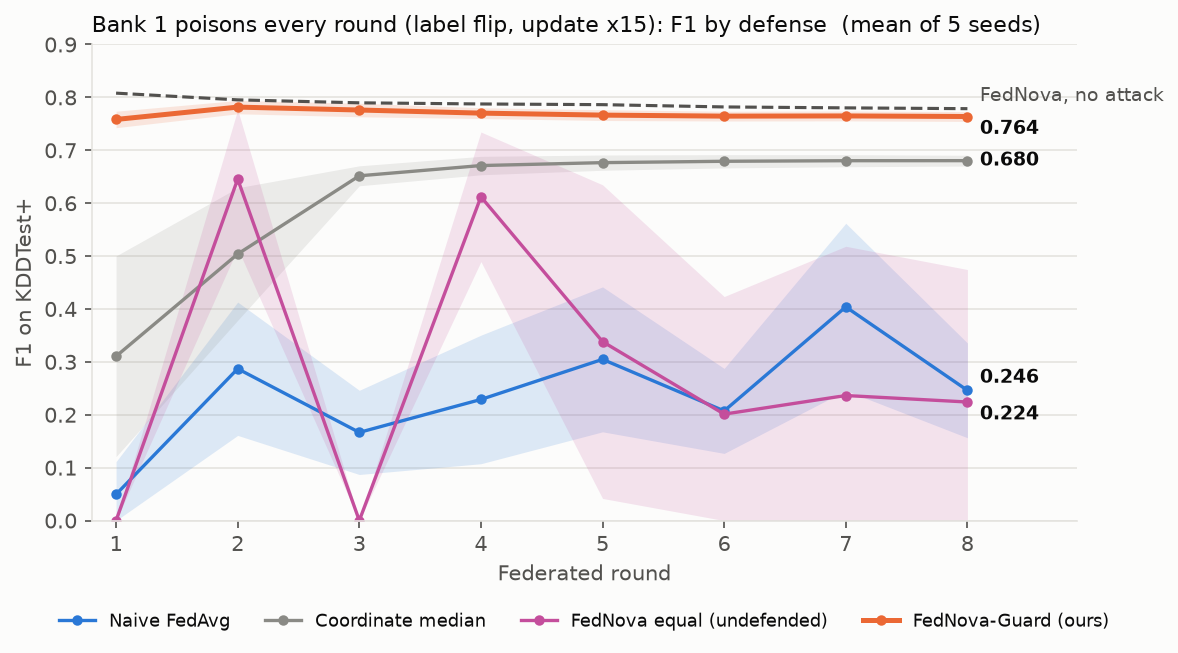

In [16]:
# F1 over rounds under the notebook attack: mean over 5 seeds, band = ±1 std
COLORS = {"Naive FedAvg": "#2a78d6", "Coordinate median": "#8a8a85",
          "FedNova equal (undefended)": "#c44e9c", "FedNova-Guard (ours)": "#eb6834"}
clean_ref = np.array([[m["f1"] for m in h] for h in seed_runs["FedNova, equal weights (non-IID)"]]).mean(0)

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(rounds, clean_ref, color=MUTED, lw=1.5, ls="--")
ax.annotate("FedNova, no attack", (8, clean_ref[-1]), xytext=(6, 6), textcoords="offset points", va="center", color=MUTED, fontsize=9)
for name, color in COLORS.items():
    f1 = np.array([[m["f1"] for m in h] for h in attack_runs[name]])
    mu, sd = f1.mean(0), f1.std(0)
    ax.fill_between(rounds, np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=color, alpha=0.15, lw=0)
    ax.plot(rounds, mu, color=color, lw=2.4 if "Guard" in name else 1.6, marker="o", ms=4, label=name)
    ax.annotate(f"{mu[-1]:.3f}", (8, mu[-1]), xytext=(6, {"FedNova-Guard (ours)": -6, "Naive FedAvg": 6, "FedNova equal (undefended)": -6}.get(name, 0)), textcoords="offset points",
                va="center", color=INK, fontsize=9, fontweight="bold")
ax.set_xlabel("Federated round", color=MUTED); ax.set_ylabel("F1 on KDDTest+", color=MUTED)
ax.set_title("Bank 1 poisons every round (label flip, update x15): F1 by defense  (mean of 5 seeds)",
             color=INK, fontsize=10.5, loc="left")
ax.set_xticks(rounds); ax.set_xlim(0.8, 8.9); ax.set_ylim(0, 0.9)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
for s in ["left", "bottom"]: ax.spines[s].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8.5, labelcolor=INK)
fig.tight_layout()
fig.savefig("figures/advanced_f1_under_attack.png", facecolor=SURFACE)
plt.show()

### What FedNova-Guard does not solve 
- **A stealthy label-flipper that keeps its update at a normal size is not detected.** It is only
  *bounded*: one fifth of the vote, clipped to at most 3× the median size. That leaves F1 at about
  0.735–0.739, against 0.764 for the oracle. We argue that no server which sees only updates can do
  better here. Under non-IID data, such an attacker looks like an honest minority bank, and detectors
  that try (Krum, cosine filters) remove the honest bank instead.
- **Lies about dataset size.** FedNova trusts reported sizes to compute τ. A bank claiming 1,000,000
  rows inflates the server step. The result is F1 0.715, better than naive FedAvg (0.208), median
  (0.677) and Multi-Krum (0.708), but noisy. Using the median τ would close this hole, but it stalls
  federations where one honest bank holds most of the data.

---
## 8. Submission (rubric-graded, no Kaggle leaderboard)

We submit to both tracks, so this cell exports two models, each with its own `submission.json`:

| Track | Model | Folder |
|---|---|---|
| 🟡 Intermediate | `custom_model`: FedNova (equal weights), non-IID, no attack | `submission_intermediate/` |
| 🔴 Advanced | `guard_model`: FedNova-Guard, non-IID, under the notebook's attack (bank 1, label flip ×15) | `submission_advanced/` |

**Input contract:** each exported model's `forward(x)` accepts the standard 41-column
preprocessed feature tensor exactly as produced in Section 1 (`FEATURE_COLS`, same order,
same scaling).

In [17]:
TEAM_NAME = "zerooth"
SUBMISSIONS = [  # (track, model, output folder)
    ("intermediate", custom_model, "submission_intermediate"),
    ("advanced",     guard_model,  "submission_advanced"),
]

for TRACK, FINAL_MODEL, OUT_DIR in SUBMISSIONS:
    os.makedirs(OUT_DIR, exist_ok=True)
    final_metrics = evaluate(FINAL_MODEL)

    FINAL_MODEL.eval()
    scripted = torch.jit.script(FINAL_MODEL)
    scripted.save(os.path.join(OUT_DIR, "model_scripted.pt"))

    submission = {
        "team_name": TEAM_NAME,
        "track": TRACK,
        "self_reported_metrics": final_metrics,
        "model_file": "model_scripted.pt",
        "n_input_features": N_FEATURES,
    }
    with open(os.path.join(OUT_DIR, "submission.json"), "w") as f:
        json.dump(submission, f, indent=2)

    print(f"{OUT_DIR}/submission.json")
    print(json.dumps(submission, indent=2), "\n")

submission_intermediate/submission.json
{
  "team_name": "zerooth",
  "track": "intermediate",
  "self_reported_metrics": {
    "precision": 0.9173,
    "recall": 0.6816,
    "f1": 0.7821
  },
  "model_file": "model_scripted.pt",
  "n_input_features": 41
} 

submission_advanced/submission.json
{
  "team_name": "zerooth",
  "track": "advanced",
  "self_reported_metrics": {
    "precision": 0.925,
    "recall": 0.6684,
    "f1": 0.776
  },
  "model_file": "model_scripted.pt",
  "n_input_features": 41
} 



### What's in the repo
- `submission_intermediate/` and `submission_advanced/`: `model_scripted.pt` + `submission.json` for each track (written by the cell above).
- `verify_submissions.py`: reloads both exported models with `torch.jit.load` and checks them against their `submission.json`.
- `experiments/` and `docs/`: every experiment behind both methods, including the ones that failed.